# PC1 Apply the PCA to the superhero-data.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/superheros.csv')
df.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   180     56 non-null     float64
 1   7       53 non-null     float64
 2   29      57 non-null     int64  
 3   7.1     56 non-null     float64
 4   17      57 non-null     int64  
 5   79      56 non-null     float64
 6   140     53 non-null     float64
dtypes: float64(5), int64(2)
memory usage: 3.2 KB


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/superheros.csv', header=None,
                 names=['Height', 'Intelligence', 'Strength', 'Speed', 'Agility', 'FightingSkills', 'Health'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Height          57 non-null     float64
 1   Intelligence    54 non-null     float64
 2   Strength        58 non-null     int64  
 3   Speed           57 non-null     float64
 4   Agility         58 non-null     int64  
 5   FightingSkills  57 non-null     float64
 6   Health          54 non-null     float64
dtypes: float64(5), int64(2)
memory usage: 3.3 KB


In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# a)
Data understanding: Briefly describe the data , i.e. what rows and columns do we have, what
kind of entries are there? Based on this: should one normalize before?

In [ ]:
print(df.describe().round(1))

       Height  Intelligence  Strength  Speed  Agility  FightingSkills  Health
count    57.0          54.0      58.0   57.0     58.0            57.0    54.0
mean    182.0           4.5      33.7    6.7     17.2            76.1   149.1
std      11.8           1.7       8.7    3.9      4.2             9.1    72.8
min     158.0           2.0      15.0    1.0     10.0            55.0    32.0
25%     175.0           3.0      27.0    4.0     14.0            70.0   101.5
50%     180.0           4.0      32.0    6.0     17.0            75.0   140.0
75%     186.0           5.0      37.8    9.0     20.0            85.0   167.5
max     222.0           9.0      50.0   20.0     30.0            95.0   375.0


We need to normalize; we can see that by observing the std, especially for Health variable compared to others. Without normalization, PC1 would just be Health because it has the highest variance.

# b)
Calculate the PCA and give out the principal components. Show the coeffients of the first principal component.

In [ ]:
X = StandardScaler().fit_transform(df.dropna())
pca = PCA().fit(X)
pcs = pd.DataFrame(pca.components_, columns=df.columns, index=[f'PC{i+1}' for i in range(7)])
print(pcs.round(2))

     Height  Intelligence  Strength  Speed  Agility  FightingSkills  Health
PC1    0.42         -0.28      0.51   0.37     0.07           -0.15    0.57
PC2   -0.43         -0.02     -0.24   0.56     0.67           -0.06    0.05
PC3   -0.18         -0.54     -0.01  -0.05    -0.03            0.81    0.12
PC4    0.11          0.70      0.31  -0.16     0.36            0.46    0.17
PC5    0.65         -0.25     -0.31  -0.27     0.54            0.00   -0.21
PC6   -0.34         -0.28      0.64  -0.39     0.33           -0.22   -0.30
PC7   -0.25         -0.04     -0.29  -0.54     0.12           -0.22    0.70


PC1 tells us how strong and big a superhero is. If Height, Strength and Health grow, so does the PC1.

# c)
Assess the number of needed dimensions

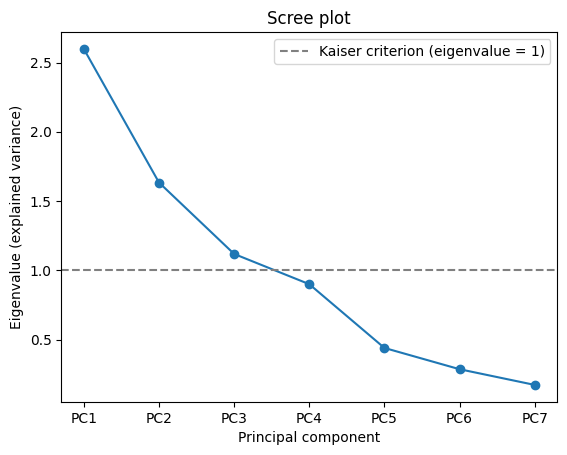

In [ ]:
plt.plot(range(1, 8), pca.explained_variance_, 'o-')
plt.axhline(1, ls='--', color='gray', label='Kaiser criterion (eigenvalue = 1)')
plt.xticks(range(1, 8), [f'PC{i}' for i in range(1, 8)])
plt.xlabel('Principal component'); plt.ylabel('Eigenvalue (explained variance)')
plt.title('Scree plot'); plt.legend(); plt.show()

Total sum of variance is 7 after normalization, y shows how many variance out of total variance does the PC cover. We use Kaiser criterion.

# d)
Iterpretation of the transformation: show the biplot with labeled variable names and describe, what you see there: what do the first 2 PC’s mean?

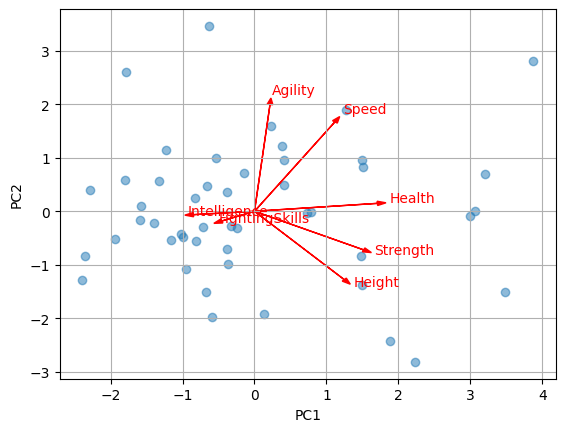

In [ ]:
Z, L = pca.transform(X), pca.components_[:2].T * 3
plt.scatter(Z[:, 0], Z[:, 1], alpha=.5)
for (x, y), c in zip(L, df.columns):
    plt.arrow(0, 0, x, y, color='r', head_width=.08); plt.text(1.1*x, 1.1*y, c, color='r')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.grid(); plt.show()

If Strength, Height, Health grows, so does PC1. If Agility and Speed grow, so does PC2.

# PC2 PCA for MNIST digit data.

In [ ]:
import numpy as np

# a)
Data understanding: Briefly describe the data , i.e. what rows and columns do we have, what kind of entries are there? Based on this: should one normalize before?

(1000, 784) 0.0 1.0 {0: 105, 1: 83, 2: 87, 3: 109, 4: 114, 5: 93, 6: 98, 7: 97, 8: 101, 9: 113}


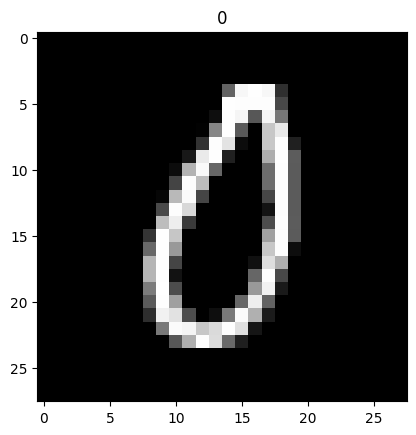

In [ ]:
X = pd.read_csv('/content/drive/MyDrive/MnistN1000.csv', header=None)
y = pd.read_csv('/content/drive/MyDrive/MNISTlabels.csv', header=None)[0] - 1   # Labels 1-10 -> digits 0-9

print(X.shape, X.values.min(), X.values.max(), y.value_counts().sort_index().to_dict())
plt.imshow(X.iloc[0].values.reshape(28, 28), cmap='gray'); plt.title(y[0]); plt.show()

All 784 columns measure the same quantity (pixel brightness) on the same scale (0–1), so differences in variance are meaningful. Central pixels vary a lot because that is where digits are written, while border pixels are almost always black. Standardizing would give these near-constant border pixels the same weight as the informative central ones, amplifying noise.

# b)
Calculate the PCA and assess the number of needed dimensions.

{0.8: 41, 0.9: 79, 0.95: 133}


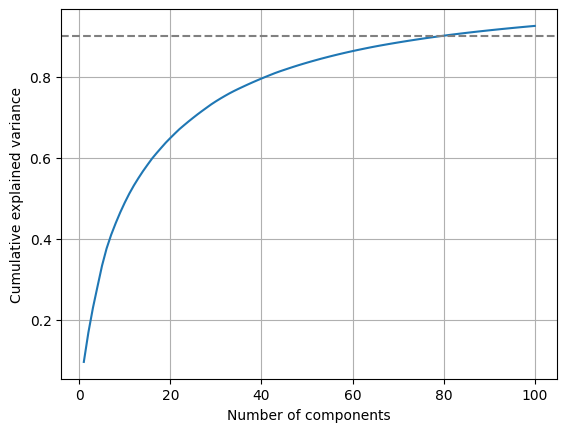

In [ ]:
pca = PCA().fit(X)
cum = pca.explained_variance_ratio_.cumsum()
print({t: int(np.argmax(cum >= t)) + 1 for t in [.8, .9, .95]})
plt.plot(range(1, 101), cum[:100]); plt.axhline(.9, ls='--', color='gray')
plt.xlabel('Number of components'); plt.ylabel('Cumulative explained variance'); plt.grid(); plt.show()

We need 79 components out of 784 to perserve the 90% variance threshold.

# c)
Assess the quality of dimension reduction by visualizing the transformed data (by reducing the
data to 2 dimensions and color coding of the 10 different digits). Can the different digits be
separated in the reduced space? Is this result expectable based on the findings of question (b)?

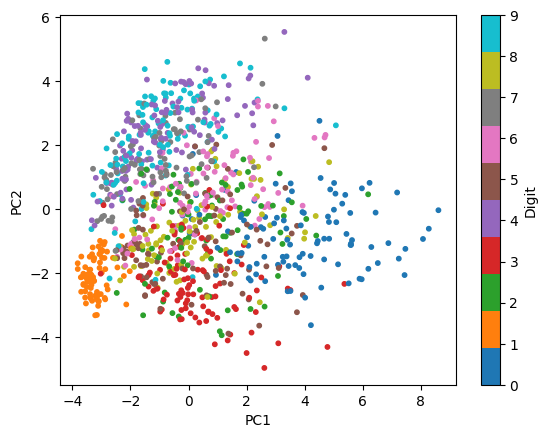

In [ ]:
Z = pca.transform(X)[:, :2]
plt.scatter(Z[:, 0], Z[:, 1], c=y, cmap='tab10', s=10); plt.colorbar(label='Digit')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.show()

The digits can only partially be separated in 2D: 1 and 0 form distinct groups, but most other digits (e.g. 4, 7, 9) overlap heavily. This is expected from (b), since the first two components explain only about 17% of the variance, while about 79 components are needed for 90%.

# PC3 Movie data

# a)
Data understanding: Briefly describe the data , i.e. what rows and columns do we have, what kind of entries are there? Based on this: should one normalize before?

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/movieData.csv', index_col=0) # we set movie names as indices

print(df.shape, df.isna().sum().sum(), np.unique(df.values))
print(df.mean().sort_values(ascending=False).round(3)) # ratio of movies per genre
print(df.sum(axis=1).value_counts().sort_index()) # how many genres does one movie have

(49999, 28) 0 [0 1]
Drama          0.404
Comedy         0.263
Romance        0.164
Family         0.133
Crime          0.132
Documentary    0.127
RealityTV      0.107
Action         0.104
Animation      0.103
Mystery        0.099
Adventure      0.086
SciFi          0.074
Thriller       0.072
Fantasy        0.065
TalkShow       0.046
News           0.042
History        0.024
Horror         0.021
Music          0.020
Western        0.019
Sport          0.016
Biography      0.016
War            0.013
GameShow       0.012
Musical        0.005
Short          0.005
Adult          0.000
Lifestyle      0.000
dtype: float64
1     20280
2     14602
3      7206
4      4236
5      2278
6       784
7       416
8       156
9        10
10       13
12       18
Name: count, dtype: int64


# b)
Apply a PCA to the movie data. How many dimensions should we keep in order to not loose too much information?

[0.19  0.134 0.111 0.085 0.06 ] {0.8: 11, 0.9: 15, 0.95: 19}


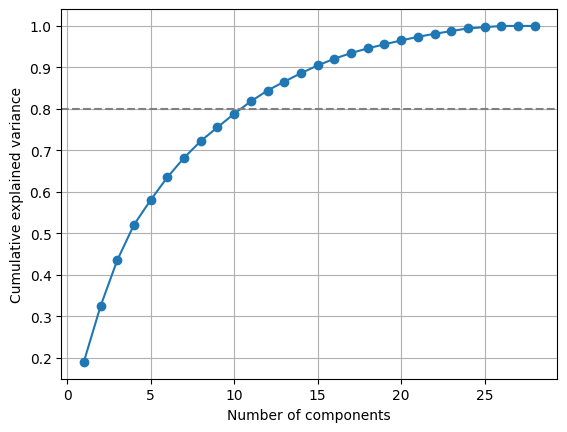

In [ ]:
# (b)
pca = PCA().fit(df)
cum = pca.explained_variance_ratio_.cumsum()
print(pca.explained_variance_ratio_[:5].round(3), {t: int(np.argmax(cum >= t)) + 1 for t in [.8, .9, .95]})
plt.plot(range(1, 29), cum, 'o-'); plt.axhline(.8, ls='--', color='gray')
plt.xlabel('Number of components'); plt.ylabel('Cumulative explained variance'); plt.grid(); plt.show()

We should keep 15 components.

# c)
Interpretation trial: Show the biplot with labeled variable names and describe, what you see there. How useful is this plot? Why or why not (depending on your answer before)?

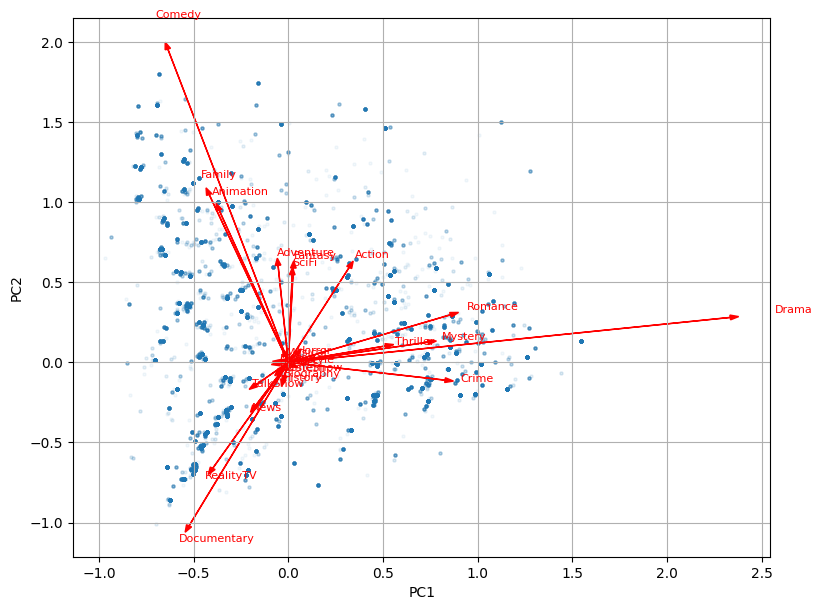

In [ ]:
# (c)
Z, L = pca.transform(df)[:, :2], pca.components_[:2].T * 3
plt.figure(figsize=(9, 7)); plt.scatter(Z[:, 0], Z[:, 1], alpha=.05, s=5)
for (x, y), c in zip(L, df.columns):
    plt.arrow(0, 0, x, y, color='r', head_width=.03); plt.text(1.1*x, 1.1*y, c, color='r', fontsize=8)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.grid(); plt.show()

PC1 is dominated by Drama (with Romance, Mystery, Thriller, Crime) versus Comedy, Documentary and RealityTV, while PC2 separates light entertainment (Comedy, Family, Animation) from non-fiction (Documentary, RealityTV, News). Most genres have tiny arrows clustered at the origin and cannot be interpreted.
The data is binary the points form a discrete grid rather than a cloud.
The plot is of limited use: as found in (b), the first two components explain only about 32% of the variance, while about 11 are needed for 80%, so most of the genre structure is lost in 2D.

# KM2 Illustrative synthetic dataset, determination of k, description of clusters.

# a)
Visualize the data: should kmeans be suitable? Cluster the balls data using kmeans.

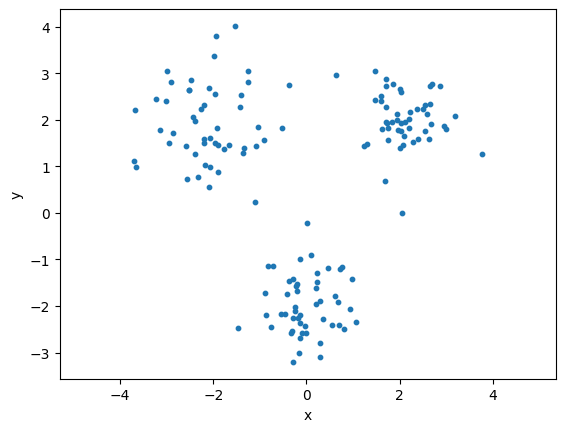

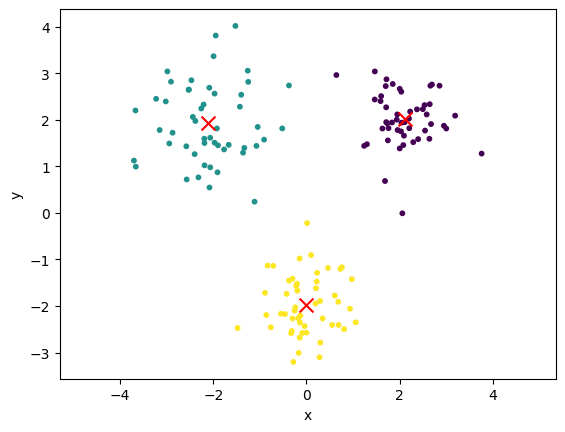

In [ ]:
from sklearn.cluster import KMeans
df = pd.read_csv('/content/drive/MyDrive/dataBalls.csv', header=None, names=['x', 'y'])

plt.scatter(df.x, df.y, s=10); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(df)
plt.scatter(df.x, df.y, c=km.labels_, s=10)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='r', marker='x', s=100)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()

K-Means is suitable because data is convex-shaped.

# b)
Determination of k: Try to choose k based on data visualization.
Try to choose the number of clusters based on the elbow method described in the lecture.
Compare the results: same/different?

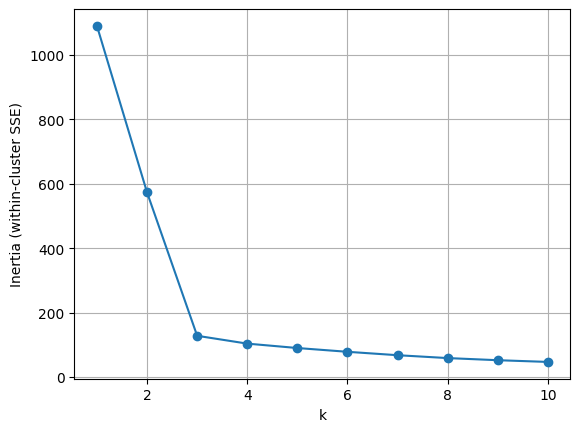

In [ ]:
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(df).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia (within-cluster SSE)'); plt.grid(); plt.show()

Elbow method also gives us k = 3 as the result, so it is the same outcome.

# c)
Interpretation/description of result: output the cluster centers.
Assess how many samples are contained in each cluster.

In [ ]:
print(pd.DataFrame(km.cluster_centers_, columns=['x', 'y']).round(2))
print(pd.Series(km.labels_).value_counts().sort_index())

      x     y
0  2.11  2.01
1 -2.11  1.92
2 -0.01 -1.97
0    50
1    50
2    50
Name: count, dtype: int64


# KM3 Illustrative synthetic datasets, determination of k, description of clusters.

# a)
Visualize the data: should kmeans be suitable? Cluster the two Moons data using kmeans. Choose k both with the generic elbow method and by visualization. Also plot the cluster centers. Is the result good?

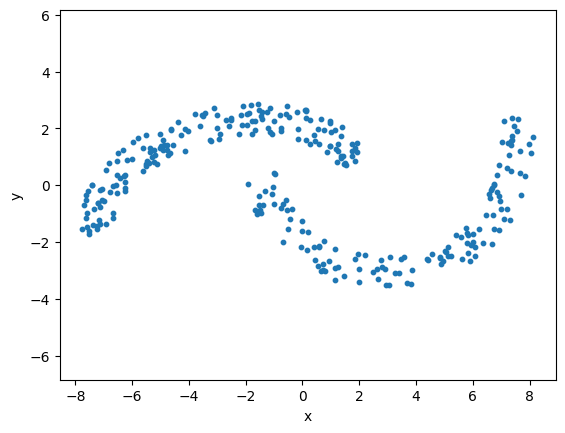

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/twoMoons.csv', header=None, names=['x', 'y'])

plt.scatter(df.x, df.y, s=10); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()

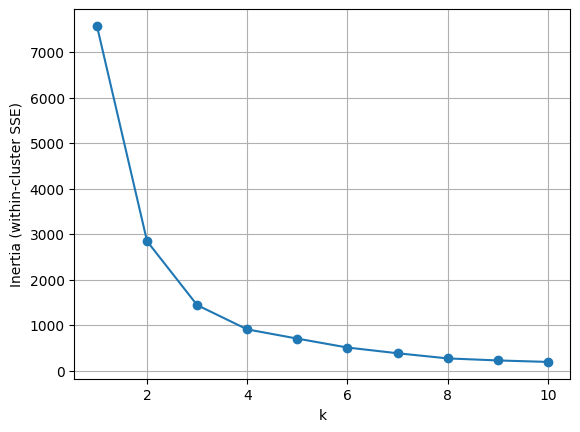

In [ ]:
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(df).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia (within-cluster SSE)'); plt.grid(); plt.show()

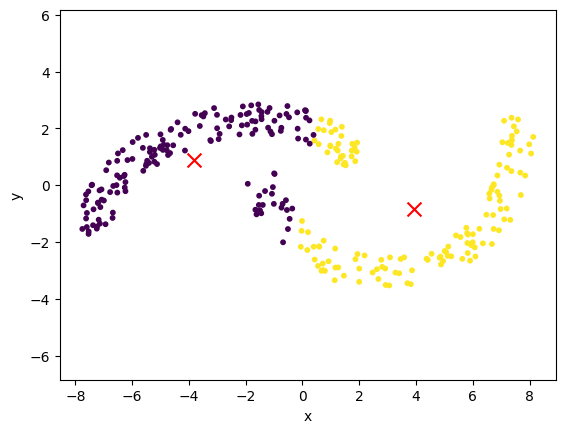

[[-3.83  0.88]
 [ 3.94 -0.82]] [158 142]


In [ ]:
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(df)
plt.scatter(df.x, df.y, c=km.labels_, s=10)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='r', marker='x', s=100)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
print(km.cluster_centers_.round(2), np.bincount(km.labels_))

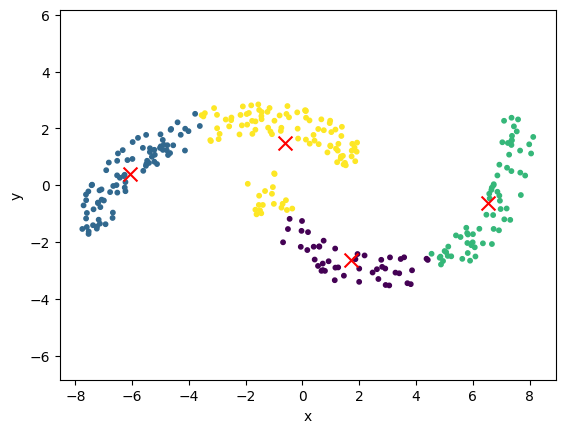

[[ 1.72 -2.64]
 [-6.08  0.39]
 [ 6.54 -0.61]
 [-0.63  1.5 ]] [ 47  82  67 104]


In [ ]:
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(df)
plt.scatter(df.x, df.y, c=km.labels_, s=10)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='r', marker='x', s=100)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
print(km.cluster_centers_.round(2), np.bincount(km.labels_))

The results are not good.

# b)
Visualize the data: should kmeans be suitable? Cluster the circles data using kmeans. Choose k both with the generic elbow method and by visualization. Also plot the cluster centers. Is the result good?

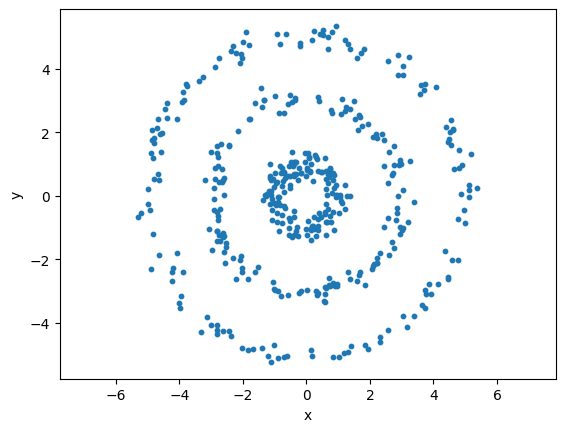

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/dataCircles.csv', header=None, names=['x', 'y'])

plt.scatter(df.x, df.y, s=10); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()

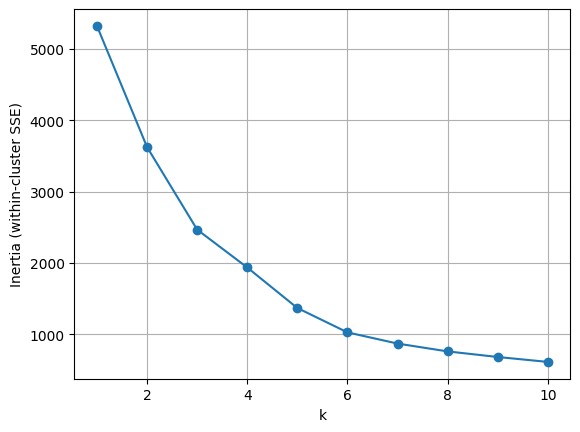

In [ ]:
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(df).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia (within-cluster SSE)'); plt.grid(); plt.show()

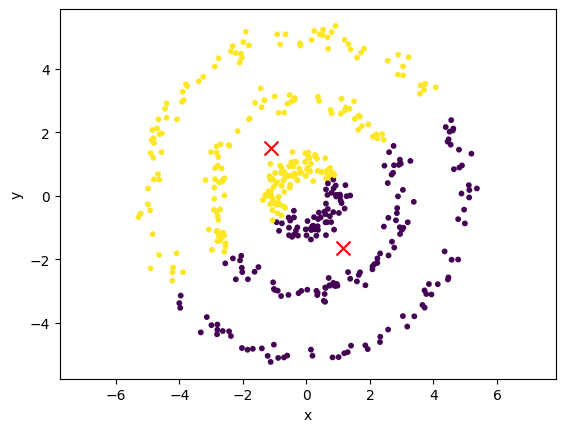

[[ 1.15 -1.65]
 [-1.12  1.52]] [208 242]


In [ ]:
km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(df)
plt.scatter(df.x, df.y, c=km.labels_, s=10)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='r', marker='x', s=100)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
print(km.cluster_centers_.round(2), np.bincount(km.labels_))

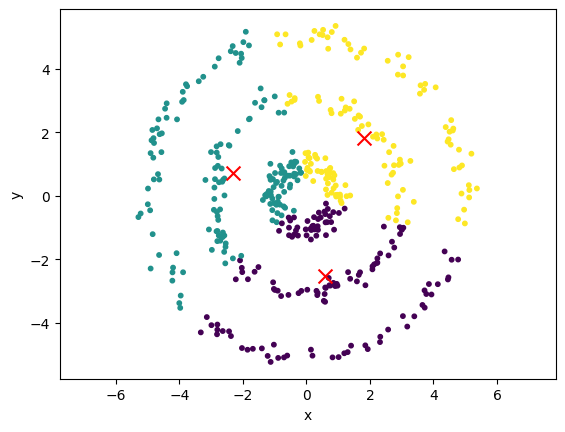

[[ 0.6  -2.52]
 [-2.3   0.72]
 [ 1.82  1.82]] [142 164 144]


In [ ]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(df)
plt.scatter(df.x, df.y, c=km.labels_, s=10)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='r', marker='x', s=100)
plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y'); plt.show()
print(km.cluster_centers_.round(2), np.bincount(km.labels_))

The results are not good.

# KM4 Movies dataset

# a)
Cluster the movies data using kmeans.
# b)
Determination of k: find a reasonable k. Is the result clear?

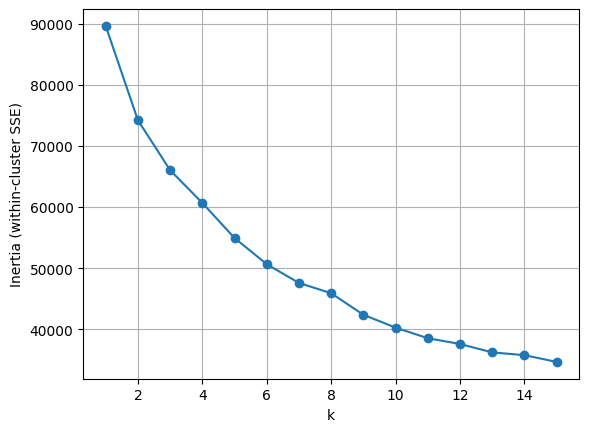

In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from wordcloud import WordCloud

df = pd.read_csv('/content/drive/MyDrive/movieData.csv', index_col=0)

# a) + b)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(df).inertia_ for k in range(1, 16)]
plt.plot(range(1, 16), inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia (within-cluster SSE)'); plt.grid(); plt.show()

# c)
Interpretation/description of result: For sake of simplicity here we set k = 5. Output the cluster
centers and use it to interpret the meaning and show the sizes of the found clusters.

In [ ]:
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(df)
C = pd.DataFrame(km.cluster_centers_, columns=df.columns).round(2)
for i in range(5): print(i, C.loc[i].nlargest(5).to_dict())
print(pd.Series(km.labels_).value_counts().sort_index())

0 {'Drama': 0.95, 'Crime': 0.89, 'Mystery': 0.83, 'Thriller': 0.55, 'Action': 0.35}
1 {'Drama': 1.0, 'Romance': 0.48, 'Action': 0.07, 'Crime': 0.06, 'Fantasy': 0.06}
2 {'Adventure': 0.71, 'Animation': 0.71, 'Action': 0.64, 'SciFi': 0.61, 'Family': 0.53}
3 {'Comedy': 1.0, 'Drama': 0.23, 'Family': 0.21, 'Animation': 0.11, 'Romance': 0.1}
4 {'Documentary': 0.33, 'RealityTV': 0.27, 'Family': 0.11, 'News': 0.11, 'TalkShow': 0.1}
0     4465
1    12679
2     3461
3    10779
4    18615
Name: count, dtype: int64


# d)
Analyze the meaning of the 5 clusters by visualizing each cluster using a WordCloud.

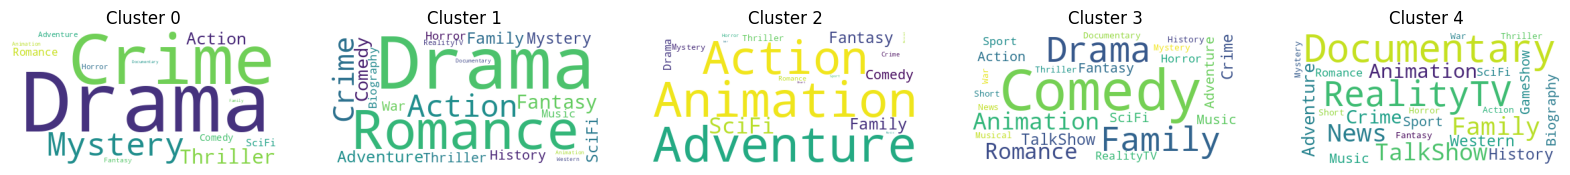

In [ ]:
f, ax = plt.subplots(1, 5, figsize=(20, 4))
for i in range(5):
    ax[i].imshow(WordCloud(background_color='white').generate_from_frequencies(C.loc[i][C.loc[i] > 0].to_dict()))
    ax[i].axis('off'); ax[i].set_title(f'Cluster {i}')
plt.show()

# e)
Note that due to the curse of dimensionality it might make sense to reduce the number of
dimensions before clustering. Therefore try to cluster the data using the dataset with reduced
dimensions by PCA (exercise PC3). Discuss difference to the result before if you find any. (Yes,
I know: very open and fuzzy question. But so is a data analyst’s life.)

In [ ]:
Z = PCA(n_components=11).fit_transform(df)
km2 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Z)
for i in range(5): print(i, df[km2.labels_ == i].mean().nlargest(5).round(2).to_dict())
print(pd.crosstab(km.labels_, km2.labels_))

0 {'Adventure': 0.76, 'Action': 0.69, 'Animation': 0.64, 'SciFi': 0.58, 'Family': 0.48}
1 {'Drama': 1.0, 'Romance': 0.51, 'Fantasy': 0.07, 'Action': 0.07, 'Comedy': 0.06}
2 {'Comedy': 1.0, 'Drama': 0.22, 'Family': 0.22, 'Animation': 0.12, 'Romance': 0.1}
3 {'Drama': 0.96, 'Crime': 0.93, 'Mystery': 0.71, 'Thriller': 0.46, 'Action': 0.3}
4 {'Documentary': 0.33, 'RealityTV': 0.26, 'News': 0.11, 'Family': 0.11, 'TalkShow': 0.1}
col_0     0      1      2     3      4
row_0                                 
0        15     91      0  4325     34
1        97  11838      0   744      0
2      3282      1    148     0     30
3       120      0  10659     0      0
4        25     11      0     0  18579


# f)
Is kmeans be suitable at all? Consider the kind of data that is assumed for kmeans and
that we have. (The comment before also applies here)

K-means is not a perfect fit for this data. It works best with continuous numbers and round, clearly separated groups, where the average of a group is a meaningful “typical” point. Our data only contains 0s and 1s (a movie either has a genre or not), so many movies are exactly the same point. The cluster centers are not real movies but percentages of genres. Also, two movies look “similar” mostly because they both lack the same genres. The elbow plot shows no clear number of clusters, and the cluster sizes are very uneven. So k-means gives a rough grouping by main genre, but a method made for 0/1 data would be a better choice.

# Declaration of AI use

AI system: Claude (Anthropic), model Claude Opus 5.5, used via the Claude app (claude.ai), November 2026.

Type and extent of use: The AI was used as a tutor and assistant throughout the exercise:

- Understanding concepts

- Code: suggested code for tasks, which I ran in Google Colab and adapted.

- Debugging: solving data loading problems and other errors.

- Text: suggested wording for most explanations and conclusions, which I checked against my own results and adapted.

- Review: checked my results and notebook and pointed out missing answers.